In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset_path = r"C:\Users\user\Documents\E-Commerce-Customer-Business-Analytics\data\processed"

print("EDA Environment Ready!")

EDA Environment Ready!


In [2]:
customers = pd.read_csv(dataset_path + r"\customers_cleaned.csv")
products = pd.read_csv(dataset_path + r"\products_cleaned.csv")
orders = pd.read_csv(dataset_path + r"\orders_cleaned.csv")
order_items = pd.read_csv(dataset_path + r"\order_items_cleaned.csv")
payments = pd.read_csv(dataset_path + r"\payments_cleaned.csv")
shipments = pd.read_csv(dataset_path + r"\shipments_cleaned.csv")
returns = pd.read_csv(dataset_path + r"\returns_cleaned.csv")
reviews = pd.read_csv(dataset_path + r"\customer_reviews_cleaned.csv")
marketing = pd.read_csv(dataset_path + r"\marketing_campaigns_cleaned.csv")

print("All 9 datasets loaded successfully!")

All 9 datasets loaded successfully!


In [3]:
datasets = {
    "Customers": customers,
    "Products": products,
    "Orders": orders,
    "Order Items": order_items,
    "Payments": payments,
    "Shipments": shipments,
    "Returns": returns,
    "Reviews": reviews,
    "Marketing": marketing
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} Rows, {df.shape[1]} Columns")

Customers: 25000 Rows, 18 Columns
Products: 550 Rows, 14 Columns
Orders: 100000 Rows, 16 Columns
Order Items: 254331 Rows, 9 Columns
Payments: 100000 Rows, 8 Columns
Shipments: 89681 Rows, 11 Columns
Returns: 12075 Rows, 8 Columns
Reviews: 77530 Rows, 8 Columns
Marketing: 151 Rows, 14 Columns


In [4]:
print("TOTAL ORDERS:", len(orders))

print("TOTAL REVENUE: ₹", round(orders["final_amount"].sum(), 2))

print("AVERAGE ORDER VALUE: ₹", round(orders["final_amount"].mean(), 2))

print("\nORDER STATUS DISTRIBUTION:")
print(orders["order_status"].value_counts())

TOTAL ORDERS: 100000
TOTAL REVENUE: ₹ 2572592368.57
AVERAGE ORDER VALUE: ₹ 25725.92

ORDER STATUS DISTRIBUTION:
order_status
Delivered     80679
Cancelled      8073
Returned       6681
Failed         2880
Processing     1687
Name: count, dtype: int64


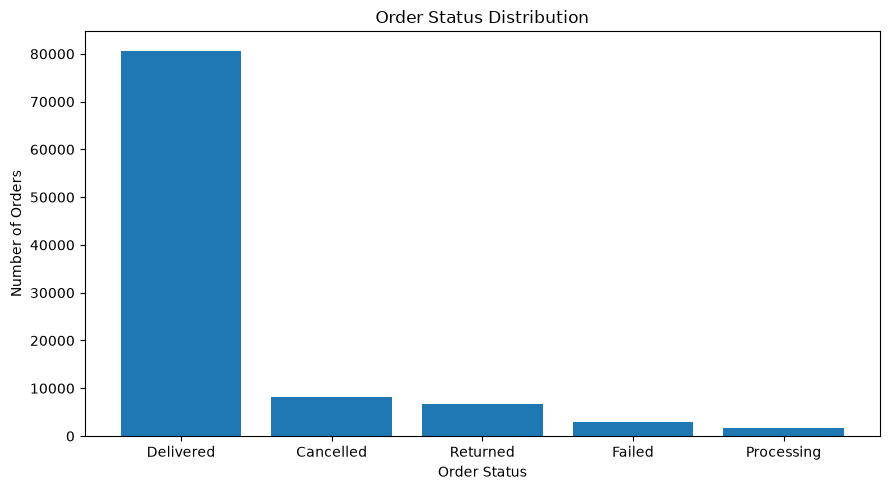

In [12]:
status_counts = orders["order_status"].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(status_counts.index, status_counts.values)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

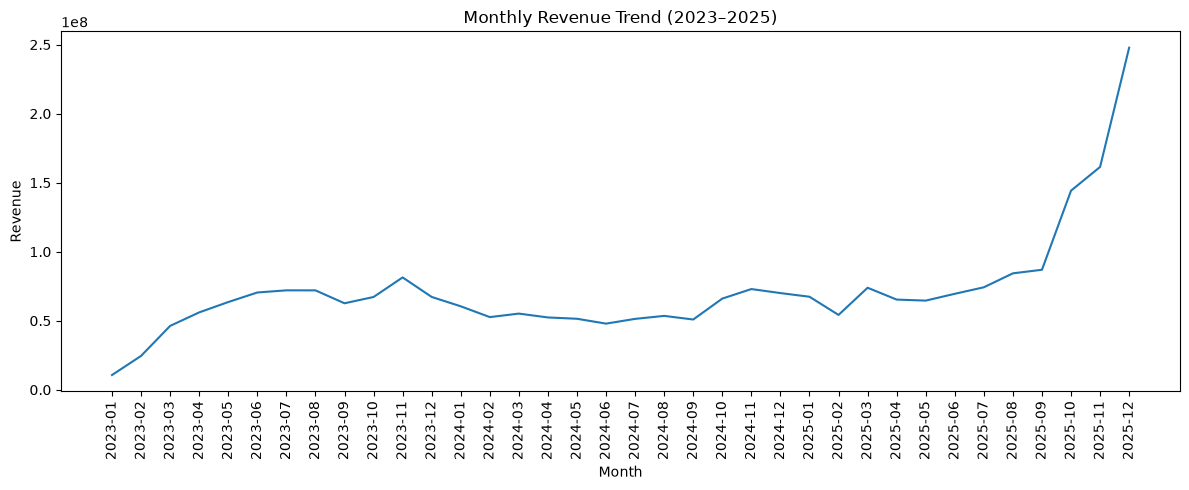

In [6]:
orders["order_date"] = pd.to_datetime(orders["order_date"])

monthly_sales = orders.groupby(
    orders["order_date"].dt.to_period("M")
)["final_amount"].sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values)

plt.title("Monthly Revenue Trend (2023–2025)")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

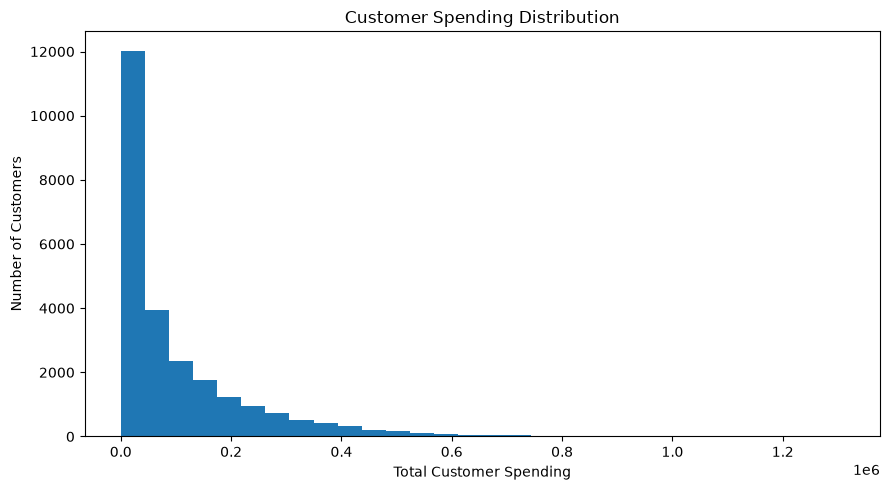

In [7]:
plt.figure(figsize=(9, 5))

plt.hist(customers["total_spend"], bins=30)

plt.title("Customer Spending Distribution")
plt.xlabel("Total Customer Spending")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

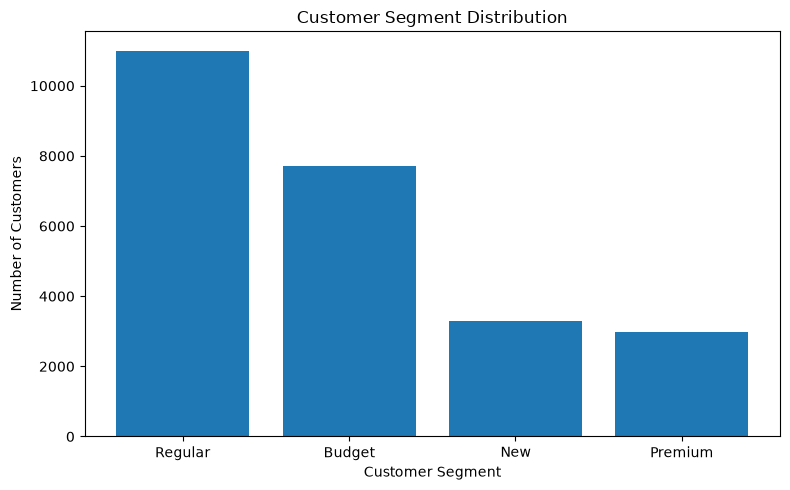

In [9]:
segment_counts = customers["customer_segment"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(segment_counts.index, segment_counts.values)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

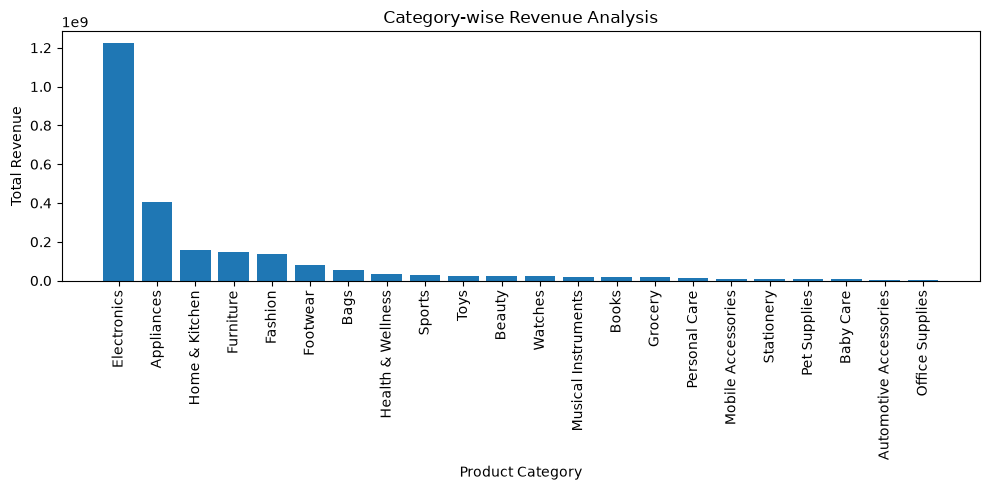

In [11]:
category_sales = order_items.merge(
    products[["product_id", "category"]],
    on="product_id"
)

category_revenue = category_sales.groupby("category")["item_revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(category_revenue.index, category_revenue.values)

plt.title("Category-wise Revenue Analysis")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

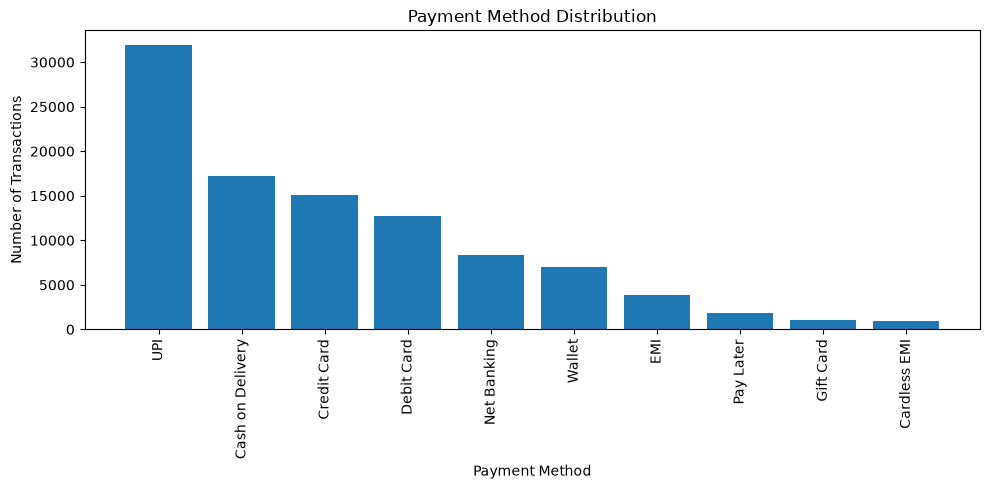

In [14]:
payment_counts = payments["payment_method"].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(payment_counts.index, payment_counts.values)

plt.title("Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

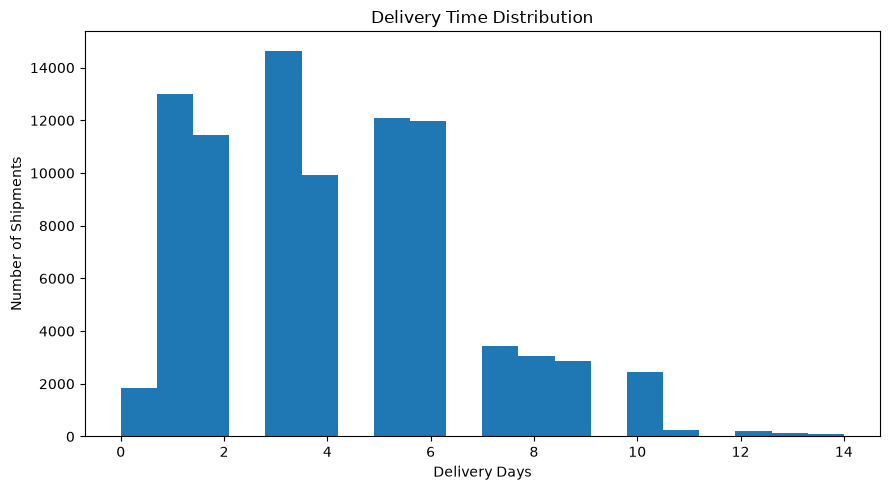

In [15]:
plt.figure(figsize=(9, 5))

plt.hist(shipments["delivery_days"].dropna(), bins=20)

plt.title("Delivery Time Distribution")
plt.xlabel("Delivery Days")
plt.ylabel("Number of Shipments")

plt.tight_layout()
plt.show()

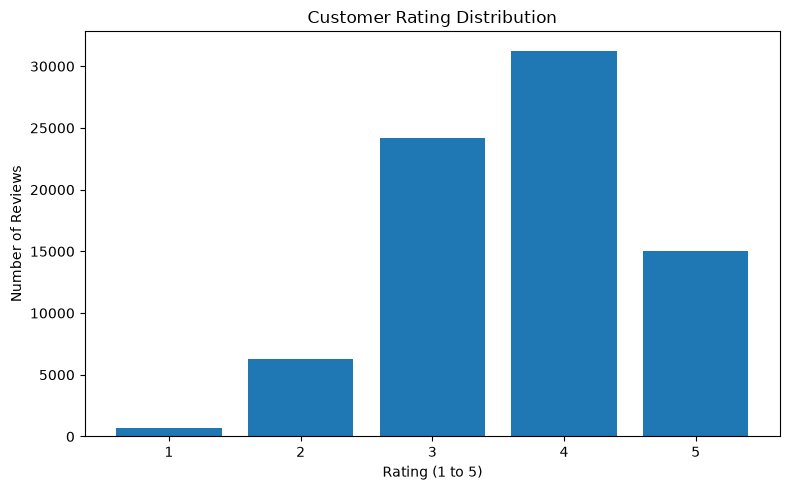

In [16]:
rating_counts = reviews["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index, rating_counts.values)

plt.title("Customer Rating Distribution")
plt.xlabel("Rating (1 to 5)")
plt.ylabel("Number of Reviews")
plt.xticks([1, 2, 3, 4, 5])

plt.tight_layout()
plt.show()

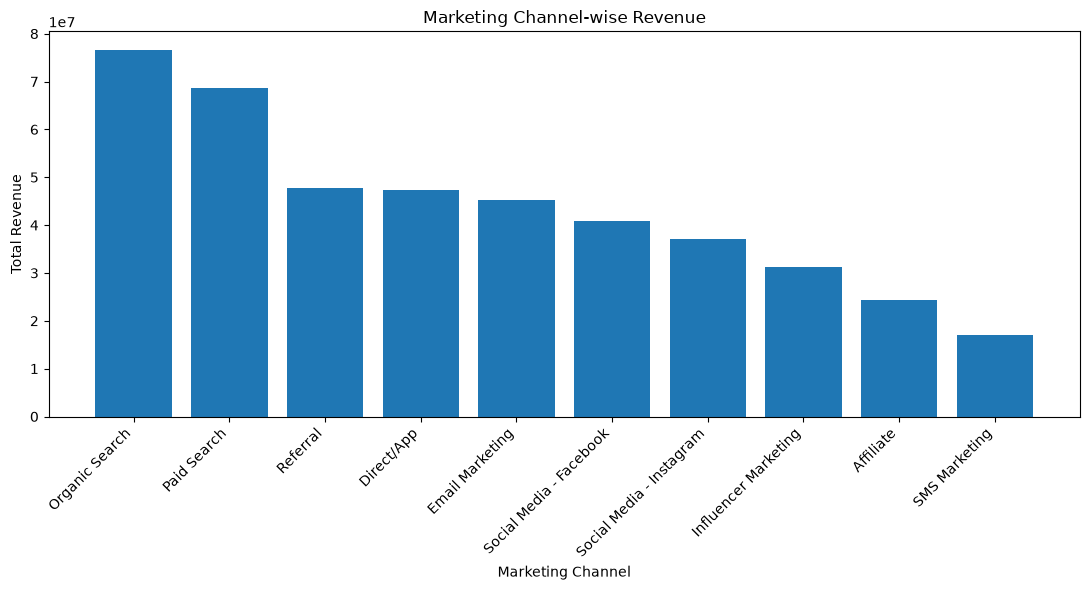

In [18]:
channel_revenue = marketing.groupby("channel")["revenue_generated"].sum().sort_values(ascending=False)

plt.figure(figsize=(11, 6))
plt.bar(channel_revenue.index, channel_revenue.values)

plt.title("Marketing Channel-wise Revenue")
plt.xlabel("Marketing Channel")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

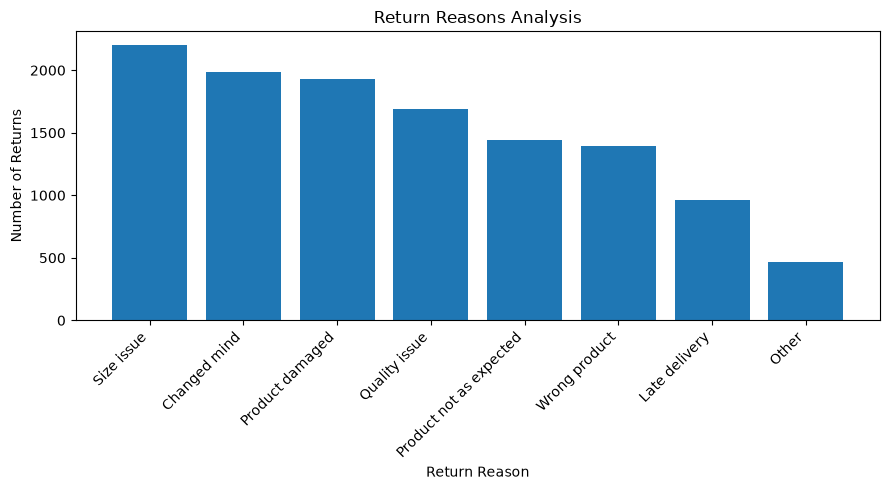

In [20]:
return_reasons = returns["return_reason"].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(return_reasons.index, return_reasons.values)

plt.title("Return Reasons Analysis")
plt.xlabel("Return Reason")
plt.ylabel("Number of Returns")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()